# Complaint monitor: which streams need escalating this week?

**Reader:** head of complaint management at a large US bank or payments firm. **Decision:** each week, which company and product complaint streams to escalate for review, and which alert rule to run.
**Data:** CFPB Consumer Complaint Database (18.7M complaints to 2026-10-26). The plan, scope, detectors and predictions were written before building anything in [research_plan.md](../research_plan.md).

## Answer in brief
- **Run a robust, alert-aware rule** (alert when a week exceeds the median of the last 26 weeks by 2.5 robust standard deviations and at least 5 complaints, with flagged weeks capped when they enter the baseline). It produces about **6 new alert episodes a week** across 250 company-by-product streams.
- **It sees what matters in big and mid-size streams:** in streams above 20 complaints a week it detects a 2x surge that lasts 4 weeks 100% of the time, and a 2x one-week burst 96% of the time (new alert within 4 weeks of onset).
- **The alert-aware baseline matters after a huge spike.** After the January 2025 Cash App wave, the standard "mean + k standard deviations" rule needed about **11,000 complaints a week** to alert, for 26 weeks, against a normal level of about 50. The alert-aware rule needed 109 to 251.
- **Small streams cannot be monitored on their own.** 114 of 250 streams get under 5 complaints a week; surges there are caught only 14% to 30% of the time. They need to be rolled up.
- **Most alerts are noise-like bursts:** about 70% of alert episodes fade within 3 weeks. Triage features (issue concentration, channel, whether it persists) help separate a filing wave from a real deterioration.

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import monitor as mo

NAVY, ORANGE, GREY, RED = "#2f4b7c", "#e08b3a", "#8a8f98", "#c0504d"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"

## 1. Scope and data hygiene
Complaint volume has exploded (18.7M in the file, mostly credit-reporting disputes), so bank products are a shrinking slice. I monitor six stable product groups, from 2018, excluding credit bureaus, student loans and debt collection.

In [2]:
raw = pd.read_parquet(mo.ALL)
raw["pg"] = raw["product"].map(mo.GROUPS)
print(f"All complaints in file: {len(raw):,} ({raw.date_received.min().date()} to {raw.date_received.max().date()})")
by_year = pd.DataFrame({"all products": raw.groupby(raw.date_received.dt.year).size(),
                        "bank product groups": raw[raw.pg.notna()].groupby(raw.date_received.dt.year).size()})
by_year["bank share"] = (by_year["bank product groups"] / by_year["all products"]).round(3)
by_year.loc[2017:]

All complaints in file: 18,681,268 (2011-12-01 to 2026-10-26)


,all products,bank product groups,bank share
date_received,,,
2017,242745,87134,0.359
2018,257130,85687,0.333
2019,277239,85142,0.307
2020,444212,102244,0.230
2021,495940,113976,0.230
2022,800245,128674,0.161
2023,1292048,165956,0.128
2024,2734268,195718,0.072
2025,5442941,323897,0.060


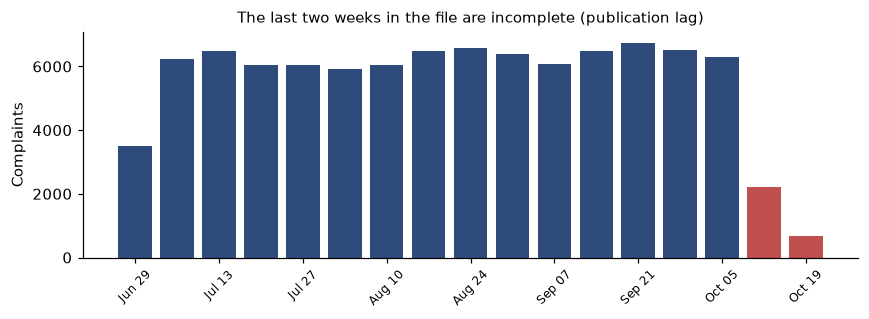

date_received
2026-09-28    6517
2026-10-05    6296
2026-10-12    2206
2026-10-19     680


In [3]:
# Publication lag: the newest weeks are incomplete, so they must not be monitored.
rb = raw[raw.pg.notna() & (raw.date_received >= "2026-07-01")]
wk = rb.groupby(rb.date_received.dt.to_period("W-SUN").dt.start_time).size()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(wk.index.strftime("%b %d"), wk.values, color=[NAVY if w <= mo.LAST_COMPLETE_WEEK else RED for w in wk.index])
ax.set_xticks(range(0, len(wk), 2), wk.index.strftime("%b %d")[::2], rotation=45, fontsize=8)
ax.set_ylabel("Complaints"); ax.set_title("The last two weeks in the file are incomplete (publication lag)", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "publication_lag.png"); plt.show()
print(wk.tail(4).to_string())

In [4]:
d = mo.load_scoped()
X = mo.weekly_streams(d)
V, weeks = X.values, list(X.columns)
print(f"In scope: {len(d):,} complaints | {X.shape[0]} monitored streams (company x product group) | {X.shape[1]} weeks, {weeks[0].date()} to {weeks[-1].date()}")
vol = pd.Series(np.median(V[:, -52:], axis=1), index=X.index)
print("\nStreams by typical weekly volume (median of last 52 weeks):")
print(mo.volume_bucket(vol).value_counts().reindex(["<5/wk", "5-20/wk", "20-100/wk", ">100/wk"]).to_string())
print("\nStreams by product group:"); print(X.index.get_level_values(1).value_counts().to_string())

In scope: 1,386,007 complaints | 250 monitored streams (company x product group) | 458 weeks, 2018-01-01 to 2026-10-05

Streams by typical weekly volume (median of last 52 weeks):
<5/wk        114
5-20/wk       84
20-100/wk     40
>100/wk       12

Streams by product group:
pg
Mortgage                    60
Checking & savings          52
Credit & prepaid cards      51
Vehicle loans               37
Money transfer & wallets    27
Personal loans              23


- **Bank products are 4% of 2026 complaints** (36% in 2017), because credit-reporting complaints grew far faster. A monitor on all complaints would be dominated by credit bureaus.
- **The latest two weeks in the file are incomplete** (2,206 and 680 complaints against about 6,300 to 6,500 for a normal week) because publication lags receipt. Monitoring them would create false "drops", so weeks after 2026-10-05 are excluded.
- **250 streams (company x product group)** are monitored. They are very uneven: 114 average under 5 complaints a week, 84 between 5 and 20, 40 between 20 and 100 and only 12 above 100. That unevenness drives most results below.

## 2. The event a monitor has to handle: January 2025

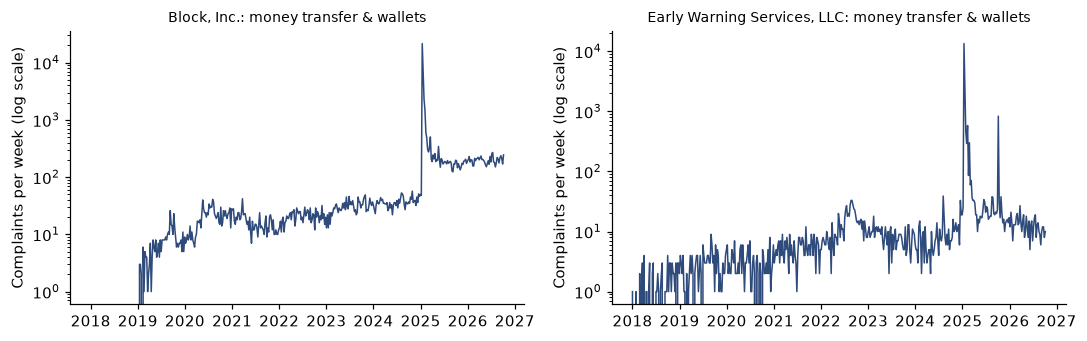

Block, week of 2025-01-13: 21608 complaints; 100% via web; top issue 'Other transaction problem' = 94%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, co in zip(axes, ["Block, Inc.", "Early Warning Services, LLC"]):
    s = X.loc[(co, "Money transfer & wallets")]
    ax.plot(s.index, s.values, color=NAVY, lw=1); ax.set_title(co + ": money transfer & wallets", fontsize=9); ax.set_yscale("log")
    ax.set_ylabel("Complaints per week (log scale)")
plt.tight_layout(); plt.savefig(FIG + "jan2025_wave.png"); plt.show()
c = d[(d.company == "Block, Inc.") & (d.pg == "Money transfer & wallets") & (d.week == "2025-01-13")]
print("Block, week of 2025-01-13:", len(c), "complaints;", f"{(c.submitted_via == 'Web').mean():.0%} via web;", f"top issue '{c.issue.value_counts().index[0]}' = {c.issue.value_counts().iloc[0] / len(c):.0%}")

In the week of 13 January 2025, Cash App (Block) received **21,608 money-transfer complaints against a normal 40 to 50**, all submitted through the website, 94% under one issue ("Other transaction problem"). Zelle's operator (Early Warning Services) had a similar wave (13,478 that week). I cannot tell the cause from this data; the pattern (one issue, one channel, a week-long burst) looks like a coordinated or event-driven wave, not a gradual deterioration. A monitor has to alert on it, and then not go blind afterwards.

## 3. Detectors, tuned to the same workload
Five rules are compared. To make the comparison fair, each is tuned so that it opens about **6 new alert episodes a week** across all streams on real history from 2023 on (new episodes are what an analyst actually triages; consecutive alert weeks in one stream count once). The workload target is my assumption about team capacity.
- **Static count:** alert at or above a fixed weekly count.
- **Mean + k SD:** the textbook rule on the previous 26 weeks.
- **Robust:** median plus k scaled MAD, with a Poisson-style floor so tiny streams cannot hair-trigger.
- **Robust, alert-aware:** the robust rule, but weeks that alert enter the history capped at the alert threshold.
- **CUSUM:** accumulated standardized excess, aimed at gradual shifts.
All rules also require at least 5 complaints above baseline.

In [6]:
ev = np.array([w >= pd.Timestamp("2023-01-02") for w in weeks])      # evaluation window: Jan 2023 onward
evidx = np.where(ev)[0]
base = mo.baselines(V)
TARGET = 6.0                                                       # NEW alert episodes per week across all streams (what an analyst triages)
def new_episodes(a):
    return a & ~np.concatenate([np.zeros((a.shape[0], 1), bool), a[:, :-1]], axis=1)      # first week of each run of alerts
specs = {"Static count": ("static", np.arange(5, 400, 1.0), {}), "Mean + k SD": ("mean_sd", np.arange(1.5, 8, 0.1), {}),
         "Robust (median/MAD)": ("robust", np.arange(1.5, 8, 0.1), {}), "Robust, alert-aware": ("robust_clean", np.arange(1.5, 8, 0.1), {}),
         "CUSUM": ("cusum", np.arange(2, 40, 0.5), {"cusum_slack": 1.0})}
def alerts_for(method, k, kw):
    return mo.detect_clean(V, k)[0] if method == "robust_clean" else mo.detect(V, method, k, base=base, **kw)[0]
cfg, rows = {}, []
for name, (method, grid, kw) in specs.items():
    rates = np.array([new_episodes(alerts_for(method, k, kw))[:, ev].sum(0).mean() for k in grid]); k = float(grid[np.argmin(np.abs(rates - TARGET))])
    a = alerts_for(method, k, kw)[:, ev]
    new = new_episodes(alerts_for(method, k, kw))[:, ev]
    cfg[name] = (method, k)
    rows.append(dict(detector=name, threshold=round(k, 2), alert_weeks_per_week=a.sum(0).mean(), new_episodes_per_week=new.sum(0).mean(),
                     mean_episode_weeks=a.sum() / max(new.sum(), 1), busiest_week=int(a.sum(0).max())))
pd.DataFrame(rows).set_index("detector").round(2)

,threshold,alert_weeks_per_week,new_episodes_per_week,mean_episode_weeks,busiest_week
detector,,,,,
Static count,17.0,49.06,5.85,8.38,77
Mean + k SD,2.3,6.95,6.09,1.14,56
Robust (median/MAD),2.5,7.95,5.79,1.37,54
"Robust, alert-aware",2.5,8.63,5.99,1.44,54
CUSUM,3.5,13.28,5.67,2.34,48


The static rule at the matched workload sits at 17 complaints and is constantly "in alert" on large streams (49 alert-weeks per week across the whole system, with average episodes of 8 weeks): it keeps flagging the same big streams and gives a dashboard that never goes quiet. The adaptive rules produce short episodes (about 1.1 to 1.4 weeks on average); CUSUM episodes last longer (2.3 weeks).

## 4. Back-test: how often is a real surge detected?
There are no labeled incidents in the data, so the test injects surges I control. I add 1.5x or 2x the baseline, for 1 week (a burst) or 4 weeks (sustained), to random quiet stream-weeks, and count it as **detected only if a new alert episode starts within 4 weeks of onset** (a stream already in alert gives no new notification). Results are split by how big the stream is.

In [7]:
scen = {"2x for 4 weeks (sustained)": (2, 4), "2x for 1 week (burst)": (2, 1), "1.5x for 4 weeks (subtle)": (1.5, 4)}
inj = {}
for label, (mult, length) in scen.items():
    inj[label] = mo.injection_test(V, evidx, cfg, mult, length, n_per_bucket=400)
order = ["Static count", "Mean + k SD", "Robust (median/MAD)", "Robust, alert-aware", "CUSUM"]
tabs = {l: r.pivot(index="bucket", columns="method", values="detect_rate")[order].reindex(["<5/wk", "5-20/wk", "20-100/wk", ">100/wk"]) for l, r in inj.items()}
for l, t in tabs.items(): print(l); print((100 * t).round(0).astype(int).to_string(), "\n")

2x for 4 weeks (sustained)
method     Static count  Mean + k SD  Robust (median/MAD)  Robust, alert-aware  CUSUM
bucket                                                                               
<5/wk                 1           28                   30                   30     30
5-20/wk              67           94                   88                   88     92
20-100/wk             2          100                  100                  100    100
>100/wk               0          100                  100                  100    100 

2x for 1 week (burst)
method     Static count  Mean + k SD  Robust (median/MAD)  Robust, alert-aware  CUSUM
bucket                                                                               
<5/wk                 1           16                   14                   14      6
5-20/wk              44           62                   54                   54     28
20-100/wk             8           97                   96                   96     79
>10

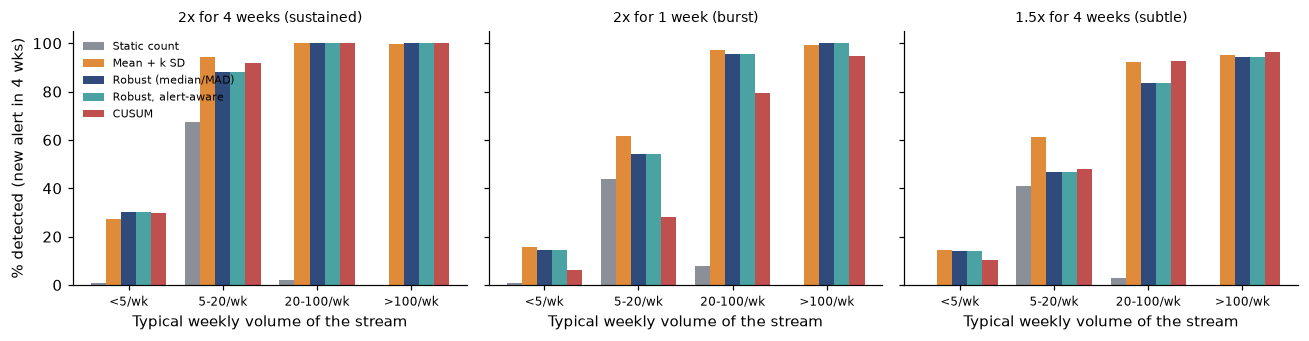

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
cols = [GREY, ORANGE, NAVY, "#4aa3a2", RED]
for ax, (l, t) in zip(axes, tabs.items()):
    w = 0.16
    for i, (m_, col) in enumerate(zip(order, cols)): ax.bar(np.arange(4) + (i - 2) * w, 100 * t[m_].values, w, color=col, label=m_)
    ax.set_xticks(range(4), t.index, fontsize=8); ax.set_title(l, fontsize=9); ax.set_xlabel("Typical weekly volume of the stream")
axes[0].set_ylabel("% detected (new alert in 4 wks)"); axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(FIG + "detection.png"); plt.show()

- **Volume decides everything.** A 2x four-week surge is caught 100% of the time in streams above 20 complaints a week, 88% to 94% at 5 to 20 a week, but only about 30% below 5 a week, where the surge is a handful of complaints inside Poisson noise.
- **In normal conditions the three adaptive rules are close** (mean + SD, robust, alert-aware). The alert-aware cap costs nothing in detection; its value shows up after a spike (next section).
- **The static threshold fails on large streams** (0% to 8% above 20 a week): they are already in alert, so a surge gives no new notification.
- **CUSUM is not the answer to subtle shifts here.** It is slightly better on a subtle 1.5x four-week surge (93% vs 84% in 20 to 100 a week streams) but much worse on bursts (79% vs 96%; 28% vs 54% in 5 to 20 a week streams), and its alerts last longer.

## 5. Baseline contamination: the weeks after the spike
A rule that learns its baseline from recent history can be blinded by a huge spike. Cash App's January 2025 wave, on each rule's threshold:

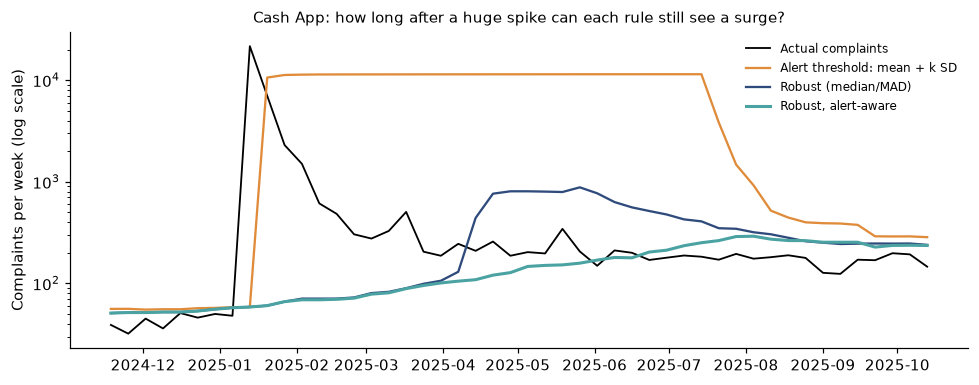

,actual,mean + k SD,robust,alert-aware
week -1,48,58,58,58
week +0,21608,59,59,59
week +1,7022,10599,60,60
week +4,612,11371,71,69
week +8,328,11396,83,81
week +13,209,11413,441,109
week +20,149,11429,770,169
week +26,183,11437,408,251
week +28,195,1474,345,289
week +35,171,376,246,254


In [9]:
s = [i for i, (c, p) in enumerate(X.index) if c == "Block, Inc." and p == "Money transfer & wallets"][0]
sp = weeks.index(pd.Timestamp("2025-01-13")); k_ms, k_rb, k_cl = cfg["Mean + k SD"][1], cfg["Robust (median/MAD)"][1], cfg["Robust, alert-aware"][1]
thr_ms = base["mean"][s] + k_ms * np.maximum(base["std"][s], 1); thr_rb = base["median"][s] + k_rb * base["sigma"][s]
a_cl, thr_cl = mo.detect_clean(V, k_cl)
lo, hi = sp - 8, sp + 40
fig, ax = plt.subplots(figsize=(9, 3.6)); x = [weeks[t] for t in range(lo, hi)]
ax.plot(x, V[s, lo:hi], color="black", lw=1.2, label="Actual complaints")
ax.plot(x, thr_ms[lo:hi], color=ORANGE, label="Alert threshold: mean + k SD"); ax.plot(x, thr_rb[lo:hi], color=NAVY, label="Robust (median/MAD)")
ax.plot(x, thr_cl[s, lo:hi], color="#4aa3a2", lw=2, label="Robust, alert-aware")
ax.set_yscale("log"); ax.set_ylabel("Complaints per week (log scale)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Cash App: how long after a huge spike can each rule still see a surge?", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "contamination.png"); plt.show()
offs = [-1, 0, 1, 4, 8, 13, 20, 26, 28, 35]
pd.DataFrame({"actual": [V[s, sp + o] for o in offs], "mean + k SD": [thr_ms[sp + o] for o in offs], "robust": [thr_rb[sp + o] for o in offs],
              "alert-aware": [thr_cl[s, sp + o] for o in offs]}, index=[f"week {o:+d}" for o in offs]).round(0).astype(int)

In [10]:
# After the spike, how many of the next 30 weeks does each rule keep alerting on Cash App?
a_rb = mo.detect(V, "robust", k_rb, base=base)[0]
print(f"Alerting weeks in the 30 weeks after the spike  alert-aware: {int(a_cl[s, sp:sp + 30].sum())} | robust: {int(a_rb[s, sp:sp + 30].sum())} | mean+SD: {int(mo.detect(V, 'mean_sd', k_ms, base=base)[0][s, sp:sp + 30].sum())}")
print(f"Median weekly complaints: 26 weeks before the spike {np.median(V[s, sp - 26:sp]):.0f} | weeks +13 to +30 after {np.median(V[s, sp + 13:sp + 30]):.0f}")

Alerting weeks in the 30 weeks after the spike  alert-aware: 22 | robust: 13 | mean+SD: 1
Median weekly complaints: 26 weeks before the spike 40 | weeks +13 to +30 after 195


- **Mean + k SD** jumped from a threshold of 59 to about **11,000** the week after the spike and stayed there for 26 weeks, while real complaints fell back to 150 to 250: it could not have flagged anything but another wave of the same size. Its alert count in the following 30 weeks was one.
- **The robust rule** held near 60 to 83 for two months, but once the decaying spike weeks filled half its window, its threshold rose to **441 to 770** (weeks 13 to 26), 3 to 5 times the new normal.
- **The alert-aware rule** stayed at 109 to 251, just above actual levels.
- **The trade-off:** Cash App's weekly complaints did not return to 40; they settled at a median of about 195 (about 5 times the old level). The alert-aware rule keeps alerting on that new level for 22 of the next 30 weeks (the robust rule 13) until its baseline catches up. In practice, an analyst needs an "acknowledge and rebaseline" action so a known, accepted level shift does not keep firing. I have not built that rule; it is the first thing to add.

## 6. What the alerts look like, and triage
For every alert, the monitor attaches the evidence an analyst needs to decide: how concentrated the issue is, what share came through the web, and whether the surge persists in the following weeks (sustained) or fades (burst).

In [11]:
a_final, thr_final = mo.detect_clean(V, k_cl)
alerts = mo.classify_alerts(V, a_final & ev[None, :], dict(median=base["median"], sigma=base["sigma"]), weeks)
alerts["company"] = [X.index[i][0] for i in alerts.stream]; alerts["product_group"] = [X.index[i][1] for i in alerts.stream]
episode = alerts.sort_values(["stream", "week"]).assign(prev=lambda x: x.groupby("stream").week.shift(1))
episode["new_episode"] = (episode.week - episode.prev) != pd.Timedelta(days=7)
ep = episode[episode.new_episode & episode.sustained.notna()]
print(f"Alert-weeks: {len(alerts):,} | new episodes: {int(episode.new_episode.sum()):,}")
print(f"Of {len(ep):,} new episodes with a follow-up window: {(~ep.sustained.astype(bool)).mean():.0%} are bursts (fade within 3 weeks), {ep.sustained.astype(bool).mean():.0%} are sustained")

Alert-weeks: 1,701 | new episodes: 1,185
Of 1,165 new episodes with a follow-up window: 70% are bursts (fade within 3 weeks), 30% are sustained


In [12]:
# Triage features for every stream-week: who and what is behind the volume
g = d.groupby(["company", "pg", "week"])
tri = g.agg(complaints=("issue", "size"), web_share=("submitted_via", lambda s: (s == "Web").mean()))
top_issue = d.groupby(["company", "pg", "week", "issue"], observed=True).size().groupby(level=[0, 1, 2]).agg(["max", "idxmax"])
tri["top_issue_share"] = top_issue["max"] / tri.complaints
tri["top_issue"] = top_issue["idxmax"].map(lambda t: t[3])
alerts = alerts.merge(tri.reset_index().rename(columns={"pg": "product_group"}), on=["company", "product_group", "week"], how="left")
recent = alerts[alerts.week >= weeks[-52]].sort_values("z", ascending=False).head(12)
recent[["week", "company", "product_group", "count", "baseline", "z", "top_issue", "top_issue_share", "web_share", "sustained"]].assign(
    week=lambda x: x.week.dt.date, baseline=lambda x: x.baseline.round(0), z=lambda x: x.z.round(1),
    top_issue_share=lambda x: (100 * x.top_issue_share).round(0), web_share=lambda x: (100 * x.web_share).round(0)).reset_index(drop=True)

,week,company,product_group,count,baseline,z,top_issue,top_issue_share,web_share,sustained
0,2026-03-09,"Bilt Technologies, Inc.",Credit & prepaid cards,38,1.0,25.0,Problem with a purchase shown on your statement,32.0,100.0,True
1,2026-02-09,"Bilt Technologies, Inc.",Credit & prepaid cards,32,1.0,20.9,"Other features, terms, or problems",22.0,97.0,True
2,2026-03-02,"Bilt Technologies, Inc.",Credit & prepaid cards,30,1.0,19.6,"Other features, terms, or problems",53.0,100.0,True
3,2026-03-16,"Bilt Technologies, Inc.",Credit & prepaid cards,28,1.0,18.2,"Other features, terms, or problems",32.0,100.0,True
4,2026-09-21,CREDIT ACCEPTANCE CORPORATION,Vehicle loans,94,21.0,15.9,Managing the loan or lease,46.0,90.0,None
5,2026-01-19,"Credit Karma, LLC",Checking & savings,35,4.0,15.5,Managing an account,74.0,97.0,True
6,2026-03-02,"Credit Karma, LLC",Checking & savings,33,4.0,12.8,Managing an account,79.0,97.0,True
7,2026-02-02,"Bilt Technologies, Inc.",Credit & prepaid cards,20,1.0,12.8,Getting a credit card,40.0,100.0,True
8,2026-03-23,"Bilt Technologies, Inc.",Credit & prepaid cards,19,1.0,12.1,"Other features, terms, or problems",32.0,100.0,True
9,2026-01-12,"Bilt Technologies, Inc.",Credit & prepaid cards,12,0.0,12.0,Getting a credit card,42.0,100.0,True


New alert episodes per week across all 250 streams, evaluation window: mean 6.0; LAST 52 weeks: mean 7.1, 90th percentile 17, max 25
Last 52 weeks with more than 10 new episodes: 11 of 52


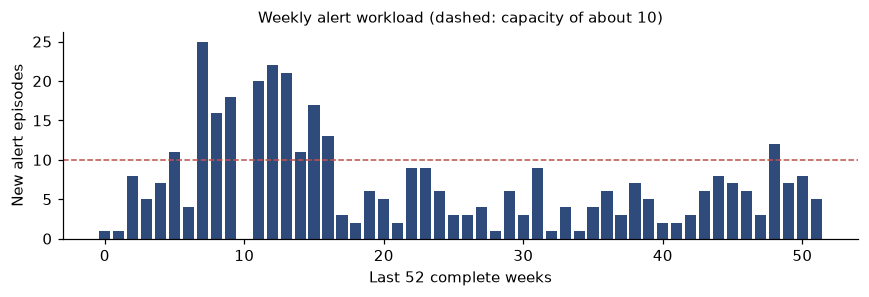

In [13]:
per_week = new_episodes(a_final)[:, -52:].sum(0)
per_week_all = new_episodes(a_final)[:, ev].sum(0)
print(f"New alert episodes per week across all {X.shape[0]} streams, evaluation window: mean {per_week_all.mean():.1f}; LAST 52 weeks: mean {per_week.mean():.1f}, 90th percentile {np.percentile(per_week, 90):.0f}, max {per_week.max()}")
print(f"Last 52 weeks with more than 10 new episodes: {(per_week > 10).sum()} of 52")
fig, ax = plt.subplots(figsize=(8, 2.8)); ax.bar(range(52), per_week, color=NAVY); ax.axhline(10, color=RED, ls="--", lw=1)
ax.set_xlabel("Last 52 complete weeks"); ax.set_ylabel("New alert episodes"); ax.set_title("Weekly alert workload (dashed: capacity of about 10)", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "workload.png"); plt.show()

- **70% of alert episodes are bursts** that fade within three weeks; **30% persist.** An escalation rule should treat these differently: a burst might be a campaign or an incident to understand; a persistent one is a deterioration to fix.
- **The strongest recent alerts are new-entrant streams** with a tiny baseline: Bilt Technologies (credit and prepaid cards) in January to March 2026, 12 to 38 complaints a week against a baseline of about 1, nearly all via the web, and **spread across several issues** (top issue 22% to 53%) rather than one, unlike Cash App's 94% single-issue wave; Credit Karma (checking and savings, same months, but concentrated: 70% to 83% under "Managing an account"); and Credit Acceptance (vehicle loans, the week of 21 September 2026: 94 against a baseline of 21).
- **Workload ran above target in the last year:** about 7.1 new episodes a week (against 6 over 2023 to 2026), with a 90th percentile of 17 and a maximum of 25, and 11 of 52 weeks above 10. Volume growth and new entrants push the rolling baseline behind. A monitor in production should be re-tuned at least twice a year and cap the weekly list at its capacity (highest z first).

In [14]:
# Persist for the app: weekly stream counts, and triage features for every stream-week in the evaluation window
import os; os.makedirs("../data/processed", exist_ok=True)
long = X.stack().rename("complaints").reset_index(); long.columns = ["company", "product_group", "week", "complaints"]
long = long[long.week >= weeks[0]]
long.to_csv("../data/processed/weekly_streams.csv.gz", index=False)
t2 = tri.reset_index().rename(columns={"pg": "product_group"})[["company", "product_group", "week", "top_issue", "top_issue_share", "web_share"]]
t2 = t2.merge(long[["company", "product_group", "week"]], on=["company", "product_group", "week"])
t2["top_issue_share"] = t2.top_issue_share.round(3); t2["web_share"] = t2.web_share.round(3)
t2.to_csv("../data/processed/triage.csv.gz", index=False)
long.shape, t2.shape

((114500, 4), (89214, 6))

## Findings
1. **Use a robust, alert-aware rule at about 6 new episodes a week.** It detects 2x four-week surges 100% of the time in streams above 20 complaints a week and 88% in 5 to 20 a week.
2. **Baseline design matters more than the choice between standard rules.** In normal weeks mean + SD, robust and alert-aware detect almost equally; after a huge spike the mean + SD rule is blind for 26 weeks (threshold about 11,000 vs 50 normal).
3. **Small streams are not monitorable on their own** (114 of 250 streams; detection 14% to 30%). Roll them up to company or product level.
4. **Most alerts are bursts (70%).** Issue concentration, channel mix and persistence separate filing waves from real deterioration.
5. **Static thresholds are the wrong tool:** they keep large streams in permanent alert and miss surges there.

## Predictions versus outcomes
| # | Prediction | Outcome |
|---|---|---|
| 1 | Robust rule finds 2x sustained surges in streams above 20 a week, does poorly below 5 | **Right:** 100% above 20 a week; 30% below 5 |
| 2 | Static threshold worst at equal workload | **Right:** 0% to 8% detection on streams above 20 a week |
| 3 | Mean + SD blinded after the January 2025 spike; robust recovers in a few weeks | **Partly right:** mean + SD blind for 26 weeks; the robust rule was fine for 8 weeks, then also inflated (threshold 3 to 5 times the new normal), and only the alert-aware version stayed close |
| 4 | Most real alerts are bursts | **Right:** 70% |
| 5 | About 10 alerts a week with over 70% detection of 2x sustained surges above 20 a week | **Right, at a lower workload:** 6 new episodes a week, 100% |
A surprise: in normal conditions the plain mean + SD rule detects about as well as the robust rules. Its weakness is entirely the post-spike blindness.

## Limits
- **Detection is measured on injected surges**, not real incidents, because the data has no incident labels. Real surges are not Poisson-shaped.
- **Unverified consumer reports.** Volume reflects awareness, campaigns and policy as well as service quality; a spike is a reason to look, not a finding of wrongdoing.
- **No normalization by company size** (accounts or customers), so large banks alert more than small ones for the same underlying rate.
- **Stream list** is chosen from whole-period totals (a mild look-ahead); workload is tuned on 2023 to 2026 and ran higher in the last year.
- **Not built:** acknowledge-and-rebaseline, roll-up of small streams, and a text layer (the file has no narratives).